Số phim: 9724
Tổng số lượt rating: 100836
count    9724.000000
mean        3.262465
std         0.869896
min         0.500000
25%         2.800000
50%         3.420000
75%         3.910000
90%         4.190000
95%         4.500000
max         5.000000
Name: average_rating, dtype: float64


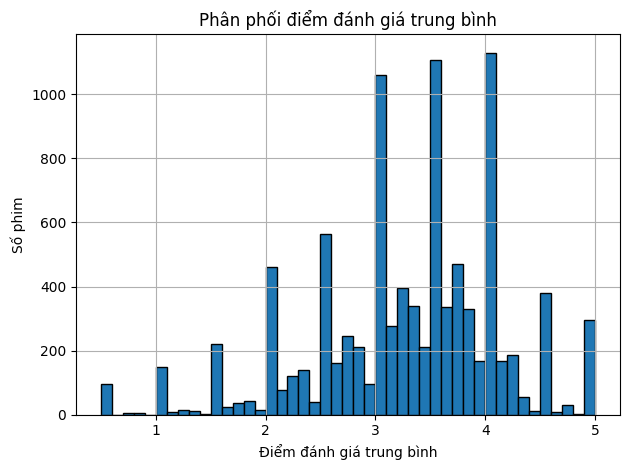

,title,rating_count,average_rating
4980,Lamerica (1994),2,5.0
4981,Heidi Fleiss: Hollywood Madam (1995),2,5.0
4982,Lesson Faust (1994),2,5.0
4983,Jonah Who Will Be 25 in the Year 2000 (Jonas q...,2,5.0
4984,Belle époque (1992),2,5.0
4985,Come and See (Idi i smotri) (1985),2,5.0
4986,Enter the Void (2009),2,5.0
6278,"Awfully Big Adventure, An (1995)",1,5.0
6279,Live Nude Girls (1995),1,5.0
6280,In the Realm of the Senses (Ai no corrida) (1976),1,5.0


,threshold,movies_remaining,percent_remaining,mean_rating,median_rating
0,10,2269,23.33,3.432,3.500
1,20,1297,13.34,3.521,3.560
2,50,450,4.63,3.663,3.755


,title,rating_count,average_rating
1235,"Streetcar Named Desire, A (1951)",20,4.47
1,"Shawshank Redemption, The (1994)",317,4.43
933,Sunset Blvd. (a.k.a. Sunset Boulevard) (1950),27,4.33
882,"Philadelphia Story, The (1940)",29,4.31
507,Lawrence of Arabia (1962),45,4.30
1012,In the Name of the Father (1993),25,4.30
21,"Godfather, The (1972)",192,4.29
883,Hoop Dreams (1994),29,4.29
976,Harold and Maude (1971),26,4.29
1013,Logan (2017),25,4.28


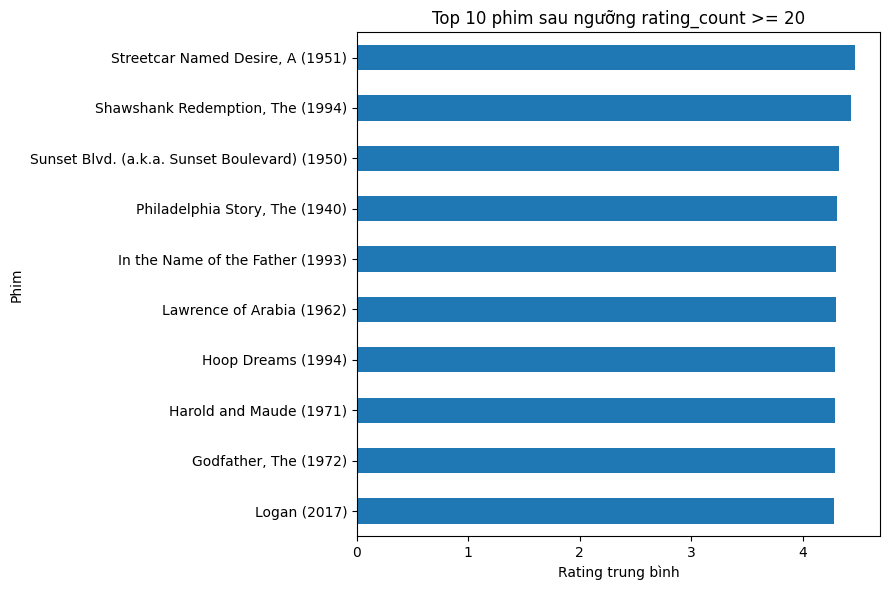

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("movie_summary.csv")

print("Số phim:", len(df))
print("Tổng số lượt rating:", df["rating_count"].sum())
print(df["average_rating"].describe(percentiles=[.25, .5, .75, .9, .95]))

df["average_rating"].hist(bins=45, edgecolor="black")
plt.xlabel("Điểm đánh giá trung bình")
plt.ylabel("Số phim")
plt.title("Phân phối điểm đánh giá trung bình")
plt.tight_layout()
plt.show()

top_before = df.sort_values(
    ["average_rating", "rating_count"], ascending=[False, False]
).head(10)
display(top_before[["title", "rating_count", "average_rating"]])

rows = []
for threshold in [10, 20, 50]:
    filtered = df[df["rating_count"] >= threshold]
    rows.append({
        "threshold": threshold,
        "movies_remaining": len(filtered),
        "percent_remaining": round(len(filtered) / len(df) * 100, 2),
        "mean_rating": round(filtered["average_rating"].mean(), 3),
        "median_rating": round(filtered["average_rating"].median(), 3)
    })
threshold_table = pd.DataFrame(rows)
display(threshold_table)

THRESHOLD = 20
filtered = df[df["rating_count"] >= THRESHOLD]
top_after = filtered.sort_values(
    ["average_rating", "rating_count"], ascending=[False, False]
).head(10)
display(top_after[["title", "rating_count", "average_rating"]])

top_after.sort_values("average_rating").plot.barh(
    x="title", y="average_rating", legend=False, figsize=(9, 6)
)
plt.xlabel("Rating trung bình")
plt.ylabel("Phim")
plt.title("Top 10 phim sau ngưỡng rating_count >= 20")
plt.tight_layout()
plt.show()

threshold_table.to_csv("so_sanh_nguong_10_20_50.csv", index=False)
top_before.to_csv("top10_truoc_nguong.csv", index=False)
top_after.to_csv("top10_sau_nguong_20.csv", index=False)


In [ ]:
from google.colab import files
uploaded = files.upload()

import pandas as pd
df = pd.read_csv('movie_summary.csv')

df.head()

Saving movie_summary.csv to movie_summary.csv


,movieId,title,genres,rating_count,average_rating
0,356,Forrest Gump (1994),Comedy|Drama|Romance|War,329,4.16
1,318,"Shawshank Redemption, The (1994)",Crime|Drama,317,4.43
2,296,Pulp Fiction (1994),Comedy|Crime|Drama|Thriller,307,4.20
3,593,"Silence of the Lambs, The (1991)",Crime|Horror|Thriller,279,4.16
4,2571,"Matrix, The (1999)",Action|Sci-Fi|Thriller,278,4.19
